<a href="https://colab.research.google.com/github/Patrick190508/whaleshark-mafia-island/blob/main/notebooks/Sites_Encounters_and_Climatology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Encounters per month and climatology of the environmental variables — Ningaloo, Donsol, Tofo

## 1 - Data Upload


In [1]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt
import seaborn as sns

!git clone -q https://github.com/Patrick190508/whaleshark-mafia-island.git repo

# find the daily files anywhere in the repo
files = glob.glob("repo/**/daily_*.csv", recursive=True)
print(files)

PATHS = {}
for f in files:
    name = os.path.basename(f).lower()
    if "ningaloo" in name: PATHS["Ningaloo"] = f
    elif "donsol" in name or "philippines" in name: PATHS["Donsol"] = f
    elif "tofo" in name or "mozambique" in name: PATHS["Tofo"] = f
print(PATHS)

# column names as in the daily files
DATE, SIGHT = "date", "sightings"
VARS = {"sst": "SST (°C)", "sss": "Salinity (PSU)", "chl": "Chlorophyll-a (mg/m³)",
        "wind": "Wind speed (m/s)", "wave": "Wave height (m)"}

data = {}
for site, path in PATHS.items():
    df = pd.read_csv(path, parse_dates=[DATE])
    df["year"], df["month"], df["doy"] = df[DATE].dt.year, df[DATE].dt.month, df[DATE].dt.dayofyear
    data[site] = df
    print(site, df[DATE].min().date(), "→", df[DATE].max().date(), len(df), "days")

['repo/data/daily_ningaloo.csv', 'repo/data/daily_mozambique.csv', 'repo/data/daily_philippines.csv', 'repo/data/daily_gulf.csv']
{'Ningaloo': 'repo/data/daily_ningaloo.csv', 'Tofo': 'repo/data/daily_mozambique.csv', 'Donsol': 'repo/data/daily_philippines.csv'}
Ningaloo 1990-01-01 → 2026-09-13 13405 days
Tofo 1990-01-01 → 2026-09-13 13405 days
Donsol 1990-01-01 → 2026-09-13 13405 days


## 2 - Sites encounters per month each year


In [8]:
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

# peak-season months used in the report
SEASON_MONTHS = {"Ningaloo": [4, 5, 6],          # Apr–Jun
                 "Donsol":   [2, 3, 4, 5],       # Feb–May
                 "Tofo":     [10, 11, 12, 1, 2]} # Oct–Feb (crosses New Year)
MIN_SIGHTINGS = 20                               # active season threshold

def active_seasons(site):
    """Years whose peak season has at least MIN_SIGHTINGS encounters.
    For Tofo, Jan–Feb belong to the season that started the previous October."""
    df = data[site]
    s = df[df["month"].isin(SEASON_MONTHS[site])].copy()
    s["season"] = np.where((site == "Tofo") & (s["month"] <= 2), s["year"] - 1, s["year"])
    totals = s.groupby("season")[SIGHT].sum()
    return set(totals[totals >= MIN_SIGHTINGS].index)

def encounters_table(site):
    """Years × months table of encounters, red (few) to green (many).
    Total column: green = active season, red = not active."""
    df = data[site]
    tab = (df.pivot_table(index="year", columns="month", values=SIGHT, aggfunc="sum")
             .reindex(columns=range(1, 13)).fillna(0).astype(int))
    tab.columns = MONTHS
    tab["Total"] = tab.sum(axis=1)

    active = active_seasons(site)
    def colour_total(col):
        return ["background-color: #63be7b" if y in active else "background-color: #f8696b"
                for y in col.index]

    print(f"{site}: {len(active)} active seasons (≥{MIN_SIGHTINGS} sightings) → {sorted(active)}")
    return (tab.style
              .background_gradient(cmap="RdYlGn", subset=MONTHS, axis=None)
              .apply(colour_total, subset=["Total"])
              .set_caption(f"{site}: encounters per month (Total: green = active season, red = not active)")
              .set_table_styles([{"selector": "caption",
                                  "props": "font-size:14px; font-weight:bold; text-align:left"}]))

### Ningaloo - West Australia



In [9]:
encounters_table("Ningaloo")

Ningaloo: 15 active seasons (≥20 sightings) → [1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009]


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Total
year,,,,,,,,,,,,,
1990,0,0,0,0,0,0,0,0,0,0,0,0,0
1991,0,0,0,0,0,0,0,0,0,0,0,0,0
1992,0,0,0,9,0,0,0,0,0,0,0,0,9
1993,0,0,0,0,0,0,0,0,0,0,0,0,0
1994,0,0,0,2,1,0,0,0,0,0,0,0,3
1995,0,0,7,5,7,11,1,0,0,0,0,0,31
1996,0,0,25,44,11,1,0,0,0,0,0,0,81
1997,0,0,2,26,9,0,0,0,0,0,0,0,37
1998,0,0,0,15,18,2,0,0,0,0,0,0,35


### Donsol - Philippines


In [10]:
encounters_table("Donsol")

Donsol: 5 active seasons (≥20 sightings) → [2006, 2007, 2008, 2009, 2010]


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Total
year,,,,,,,,,,,,,
1990,0,0,0,0,0,0,0,0,0,0,0,0,0
1991,0,0,0,0,0,0,0,0,0,0,0,0,0
1992,0,0,0,0,0,0,0,0,0,0,0,0,0
1993,0,0,0,0,0,0,0,0,0,0,0,0,0
1994,0,0,0,0,0,0,0,0,0,0,0,0,0
1995,0,0,0,0,0,0,0,0,0,0,0,0,0
1996,0,0,0,0,0,0,0,0,0,0,0,0,0
1997,0,0,0,0,0,0,0,0,0,0,0,0,0
1998,0,0,0,0,0,0,0,0,0,0,0,0,0


### Tofo - Mozambique

In [11]:
encounters_table("Tofo")

Tofo: 5 active seasons (≥20 sightings) → [2005, 2006, 2007, 2008, 2009]


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Total
year,,,,,,,,,,,,,
1990,0,0,0,0,0,0,0,0,0,0,0,0,0
1991,0,0,0,0,0,0,0,0,0,0,4,0,4
1992,0,0,0,0,0,0,0,0,0,0,0,0,0
1993,0,0,0,0,0,0,0,0,0,0,0,0,0
1994,0,0,0,0,0,0,0,0,0,0,0,0,0
1995,0,0,0,0,0,0,0,0,0,0,0,0,0
1996,0,0,0,0,0,0,0,0,0,0,0,0,0
1997,0,0,0,0,0,0,0,0,0,0,0,0,0
1998,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3 - Climatology


In [13]:
# same style as the first daily EDA: median + interquartile band, grey = peak season,
# blue bars = sightings per day of year summed over the active seasons
CLIM_VARS = [("sst",  "SST (°C)",              "tab:red"),
             ("chl",  "chlorophyll-a (mg/m³)", "tab:green"),
             ("sss",  "salinity (PSU)",        "tab:purple"),
             ("wind", "wind speed (m/s)",      "tab:orange"),
             ("wave", "wave height (m)",       "tab:cyan")]

SITE_TITLE = {"Ningaloo": "Ningaloo Reef (W Australia)",
              "Donsol":   "Donsol (Philippines)",
              "Tofo":     "Tofo (Mozambique)"}

month_starts = pd.to_datetime([f"2001-{m:02d}-01" for m in range(1, 13)]).dayofyear

def shade_season(ax, site):
    """Grey band over the peak-season months (Tofo wraps over New Year)."""
    months = SEASON_MONTHS[site]
    runs, run = [], [months[0]]
    for m in months[1:]:
        if m == run[-1] + 1: run.append(m)
        else: runs.append(run); run = [m]
    runs.append(run)
    for r in runs:
        start = month_starts[r[0] - 1]
        end = month_starts[r[-1]] if r[-1] < 12 else 366
        ax.axvspan(start, end, color="grey", alpha=0.15, zorder=0)

def climatology_plot(site):
    df = data[site]
    first, last = df["year"].min(), df["year"].max()

    # sightings per day of year, active seasons only
    active = active_seasons(site)
    season_year = np.where((site == "Tofo") & (df["month"] <= 2), df["year"] - 1, df["year"])
    bars = df[np.isin(season_year, list(active))].groupby("doy")[SIGHT].sum().reindex(range(1, 367), fill_value=0)

    fig, axes = plt.subplots(len(CLIM_VARS), 1, figsize=(14, 3.6 * len(CLIM_VARS)))
    for ax, (col, label, colour) in zip(axes, CLIM_VARS):
        q = df.groupby("doy")[col].quantile([0.25, 0.5, 0.75]).unstack().reindex(range(1, 367))
        shade_season(ax, site)
        ax2 = ax.twinx()
        ax2.bar(bars.index, bars.values, width=1, color="cornflowerblue", alpha=0.5, zorder=1)
        ax2.set_ylabel("sightings", color="tab:blue")
        ax.fill_between(q.index, q[0.25], q[0.75], color=colour, alpha=0.2, zorder=2)
        ax.plot(q.index, q[0.5], color=colour, lw=1.4, zorder=3)
        ax.set_ylabel(label)
        ax.set_xlim(1, 366)
        ax.set_xticks(month_starts); ax.set_xticklabels(MONTHS)
        ax.grid(alpha=0.3)
        ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)   # line above the bars
    axes[0].set_title(f"{SITE_TITLE[site]} — daily climatology {first}–{last} "
                      "(median, interquartile band); grey = peak season; bars = sightings (active years)",
                      loc="left")
    plt.tight_layout()
    plt.savefig(f"climatology_{site.lower()}.png", dpi=200, bbox_inches="tight")
    plt.show()

### Ningaloo - West Australia

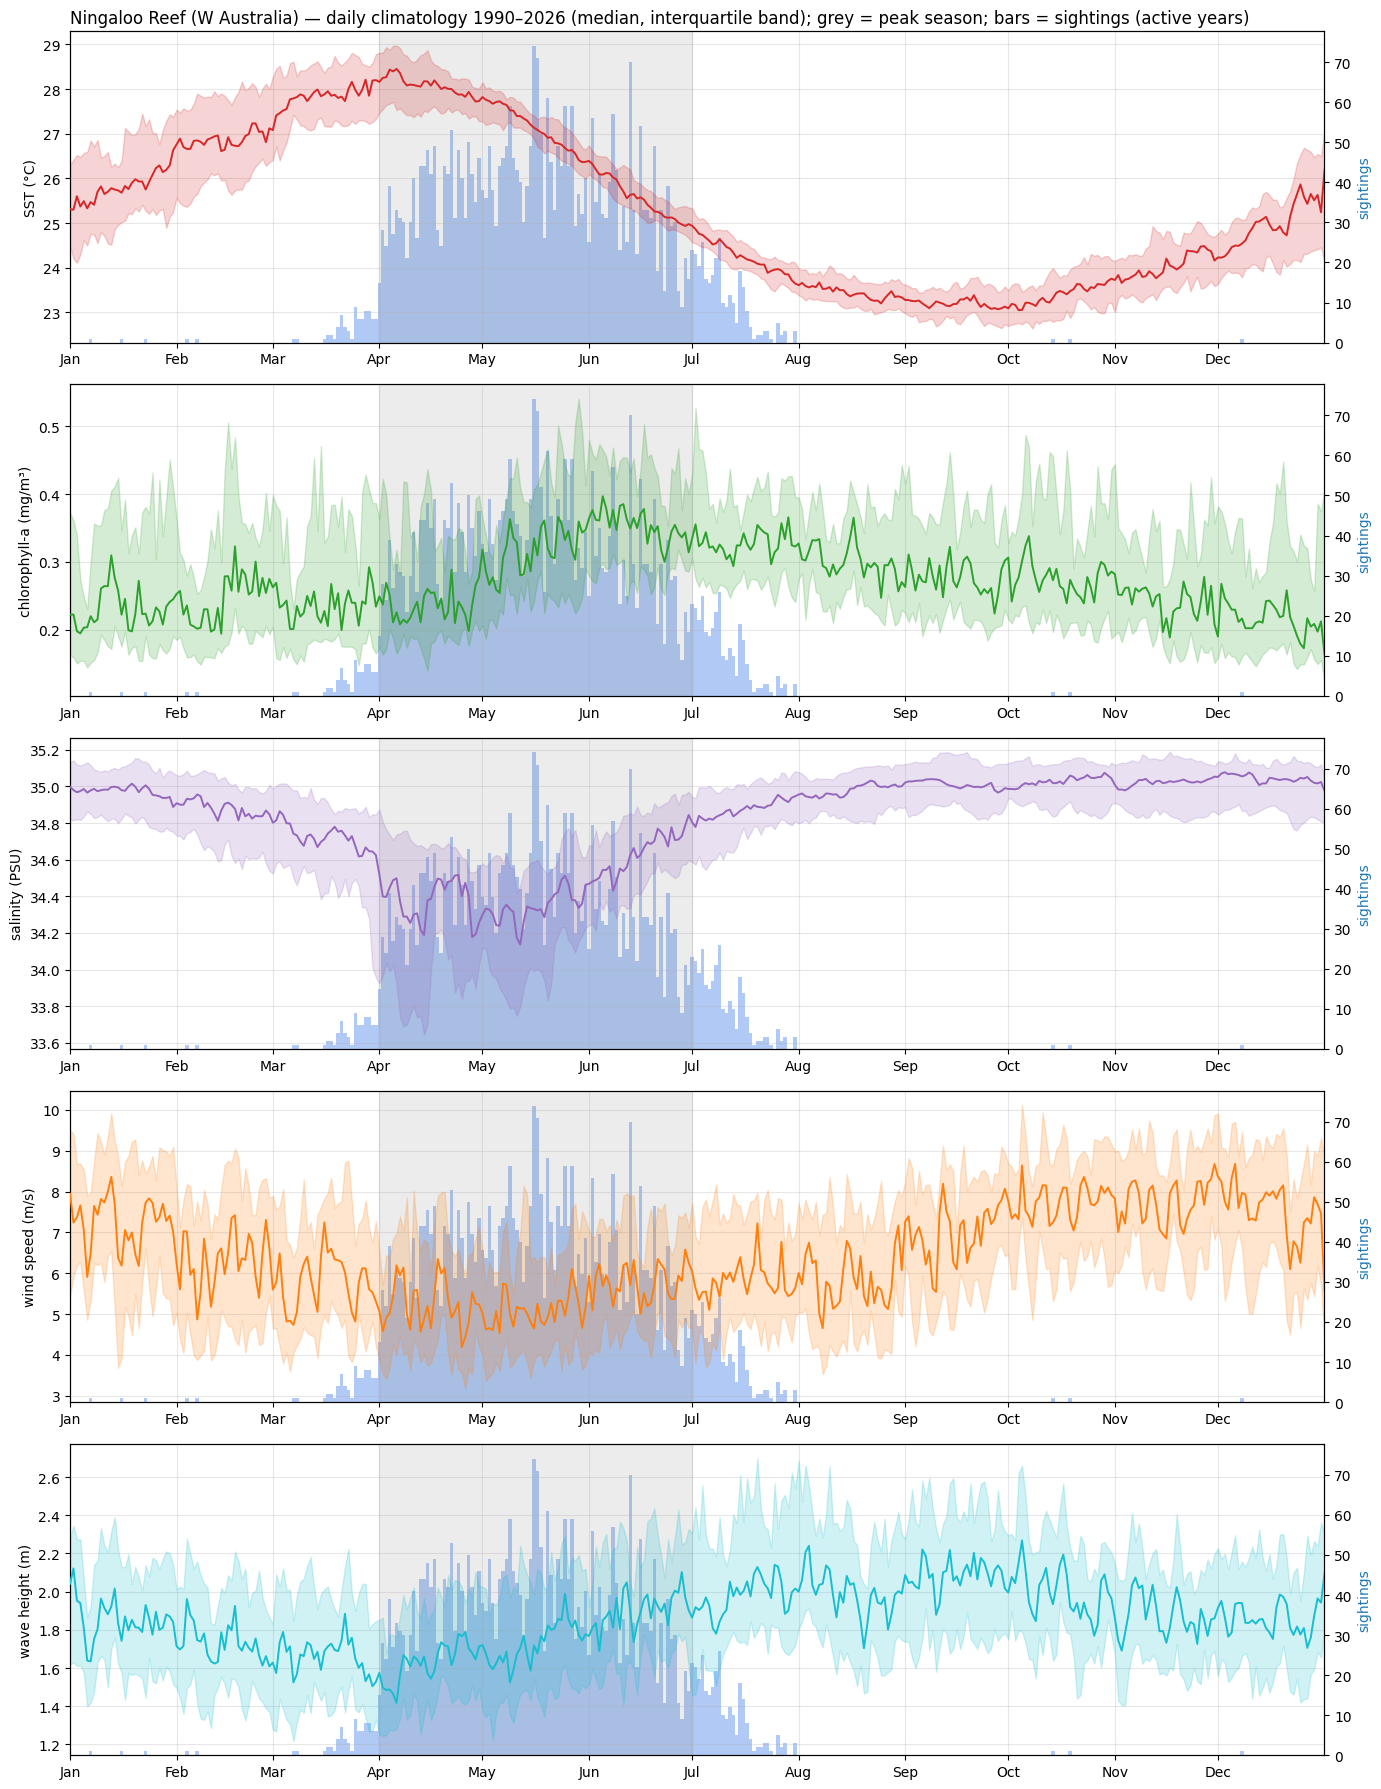

In [14]:
climatology_plot("Ningaloo")

### Donsol - Philippines


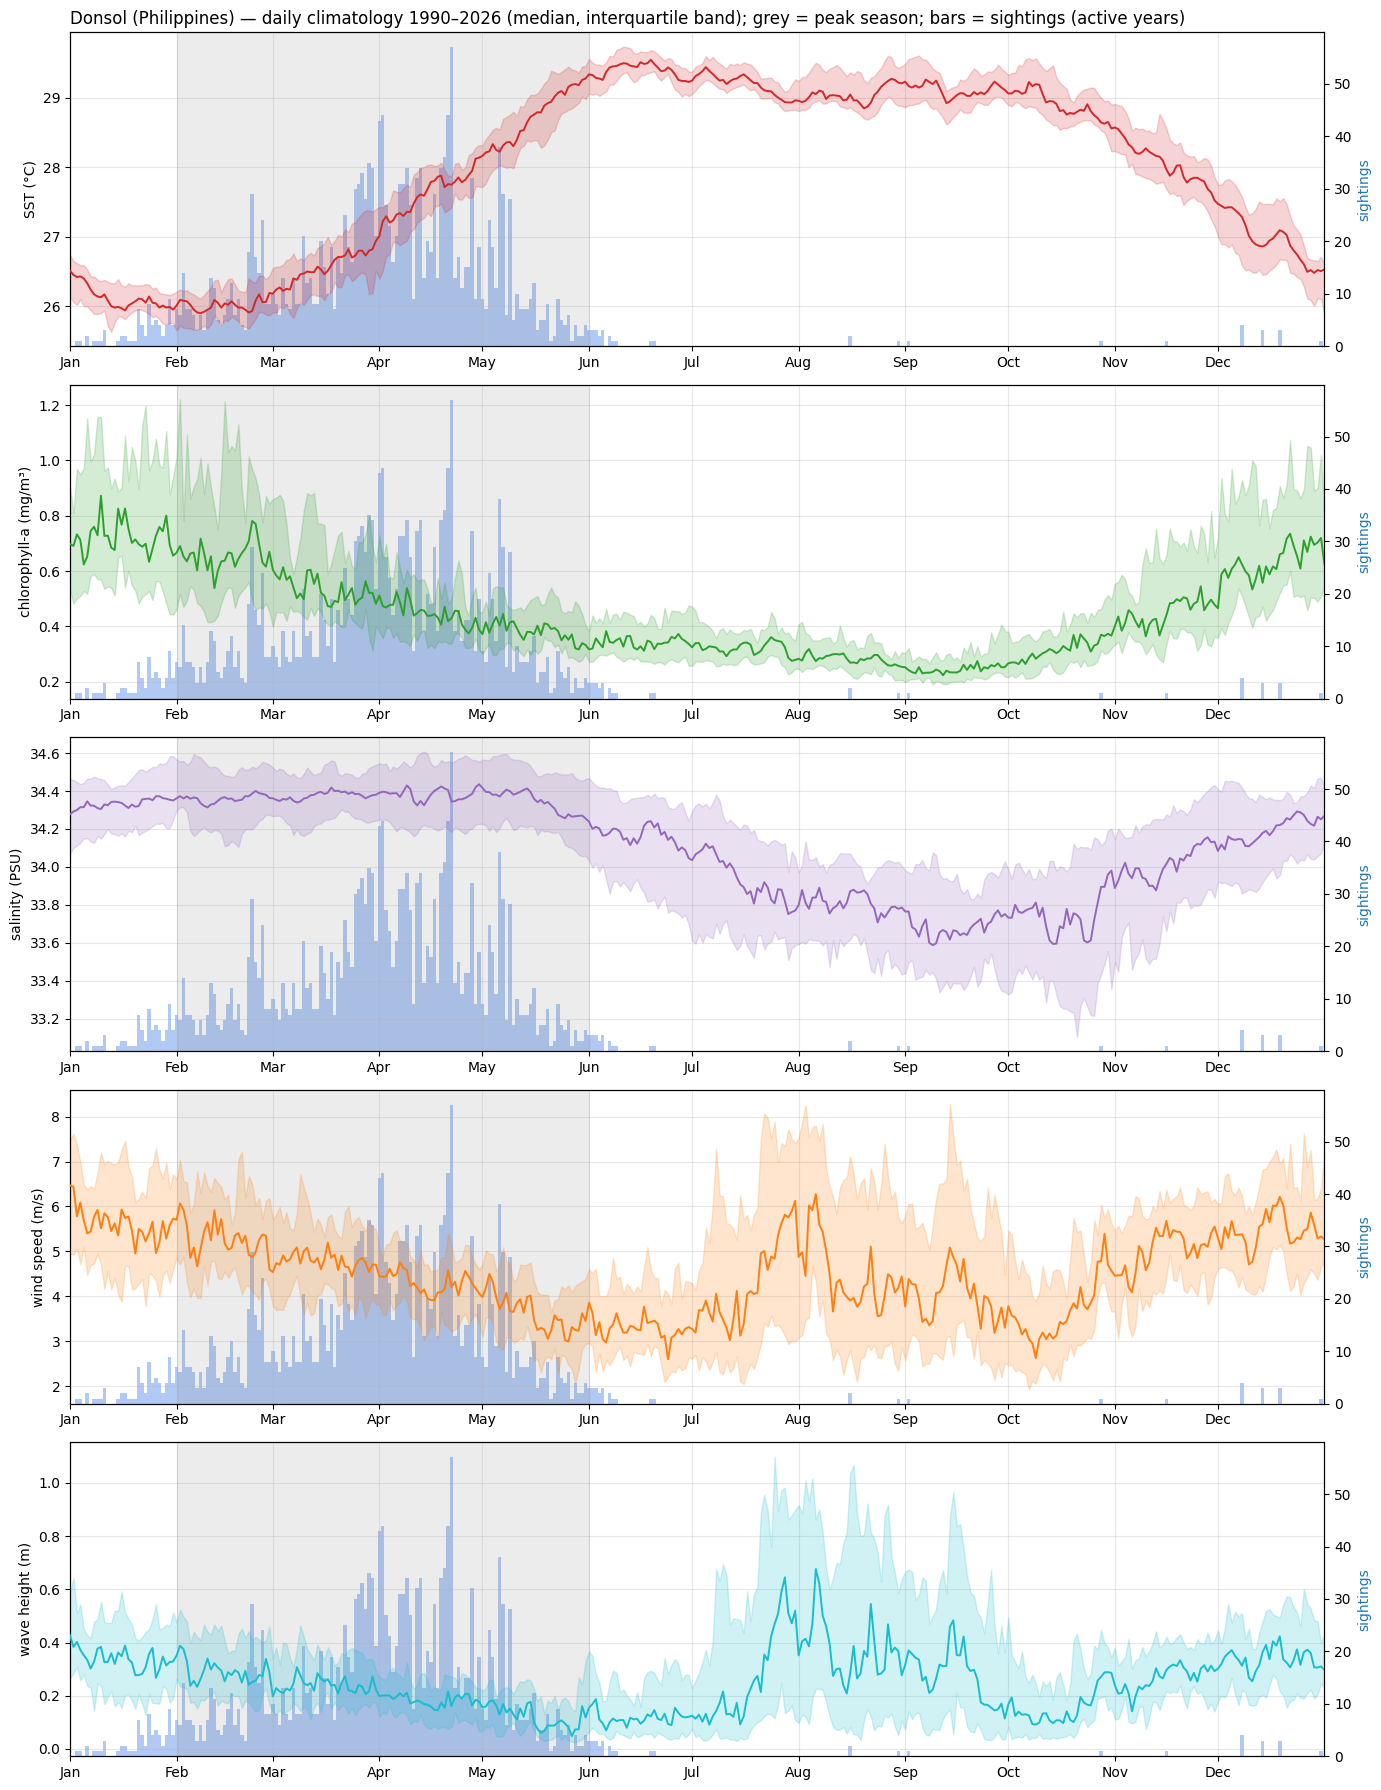

In [15]:
climatology_plot("Donsol")

### Tofo - Mozambique

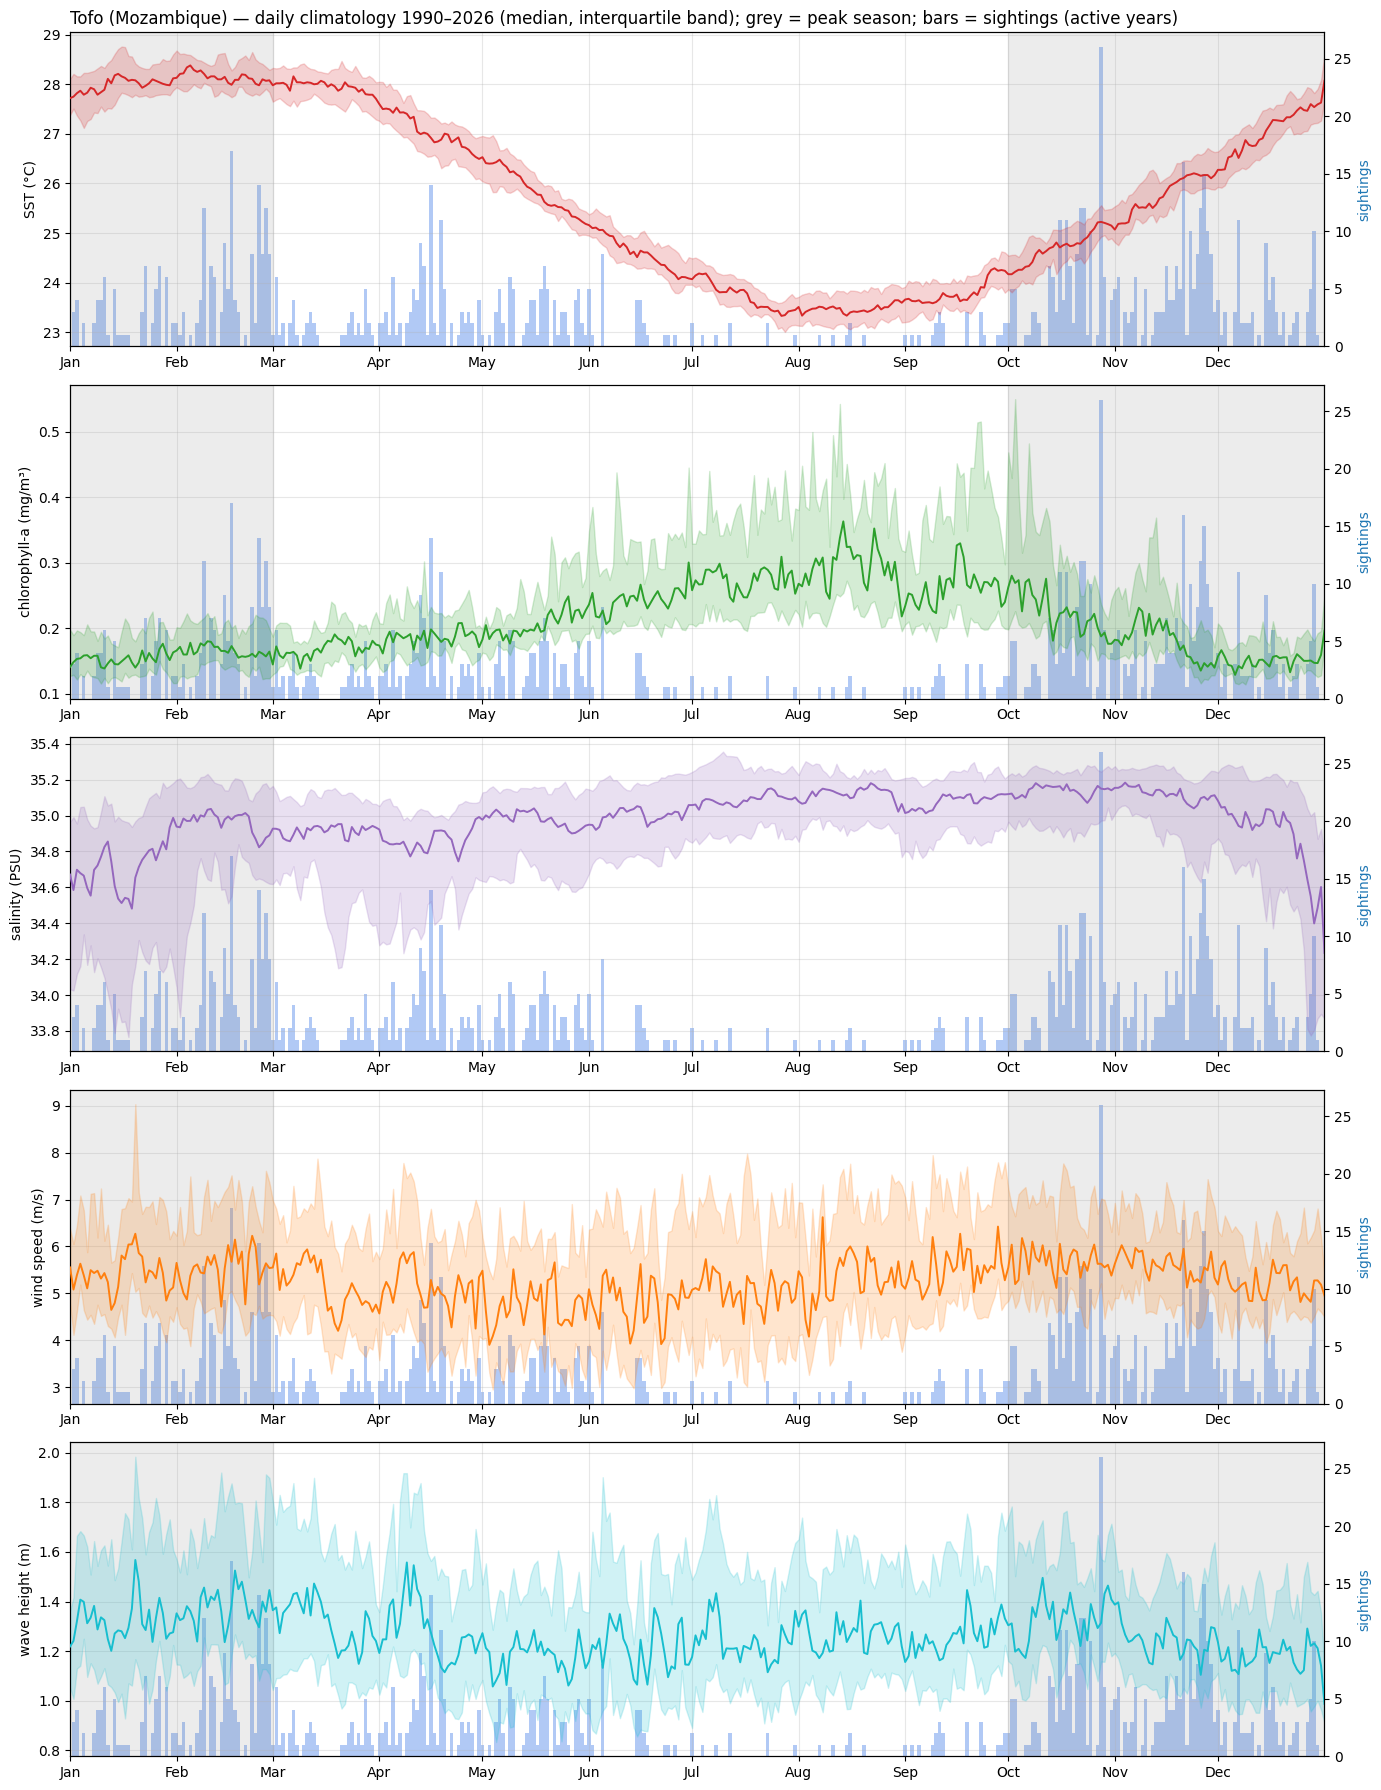

In [16]:
climatology_plot("Tofo")